In [1]:
import sys
import os

# Set project root relative to notebook location
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

In [2]:
import numpy as np
import scipy
from sklearn.linear_model import GammaRegressor
import mbtr.utils as ut
import scipy.special as special
import matplotlib.pyplot as plt
from mbtr.mbtr import MBT
from mbtr.utils import set_figure
from mbtr import LOSS_MAP
from Losses import GammaLoss
from Losses.GammaLoss import GammaLikelihood
from Losses import LognormalLoss
from Losses.LognormalLoss import LognormalLikelihood

LOSS_MAP['gamma'] = GammaLikelihood
LOSS_MAP['lognormal'] = LognormalLikelihood

c:\Users\antho\master-thesis-project\mbtr39env\lib\site-packages\llvmlite\binding\ffi.py:175: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [3]:
def mse(y, y_pred):
    return np.mean((y-y_pred)**2)

def sum_of_squares(y, y_pred):
    return np.sum((y-y_pred)**2)

def r_squared(y, y_pred, y_bar):
    return (1 - sum_of_squares(y, y_pred)/sum_of_squares(y, y_bar))

In [ ]:
np.random.seed(43)
n = 10000

x = np.random.uniform(0, 1, (n, 3))
x1 = x[:, 0]
x2 = x[:, 1]
x3 = x[:, 2]

beta = [1, 2, 3, 4, 5]
delta = [4, 3, 2, 1]

#test
#gamma:
filt = (x1 <= 0.5)
alpha_test = np.zeros(n)
theta_test = np.zeros(n)
alpha_test[filt] = 1.0
alpha_test[~filt] = 3.0
theta_test[filt] = 5.0
theta_test[~filt] = 2.0

#lognormal:
sigma_test = np.zeros(n)
mu_test = np.zeros(n)
sigma_test[filt] = 1.0
sigma_test[~filt] = 3.0
mu_test[filt] = -2.0
mu_test[~filt] = 2.0

# simple linear relationship
# gamma:
alpha0 = np.exp(beta[0] + beta[1]*x1 + beta[2]*x2 + beta[3]*x3)
theta0 = np.exp(delta[0] + delta[1]*x1 + delta[2]*x2 + delta[3]*x3)
#lognormal
mu0 = beta[0] + beta[1]*x1 + beta[2]*x2 + beta[3]*x3
sigma0 = np.exp(delta[0] + delta[1]*x1 + delta[2]*x2 + delta[3]*x3)

# non-linear relationship with interaction effects
# gamma:
alpha1 = np.exp(beta[0] + beta[1]*x1 + beta[2]*x2 + beta[3]*x3 + beta[4]*x1*x3)
theta1 = np.exp(delta[0] + delta[1]*(5*x1**2 + np.sin(1.5*x1)) + delta[2]*x2 + delta[3]*x3)

# lognormal:
mu1 = beta[0] + beta[1]*x1 + beta[2]*x2 + beta[3]*x3 + beta[4]*x1*x3
sigma1 = np.exp(delta[0] + delta[1]*(5*x1**2 + np.sin(1.5*x1)) + beta[2]*x2 + beta[3]*x3)

# highly non-linear relationship with strong interaction effects
# gamma:
alpha2 = np.exp(beta[0] + beta[1]*(x1 < 0.3) + beta[2]*np.sin(2*np.pi*x2) + beta[3]*x3**2 + beta[4]*x3*(np.abs(x2) > 0.5))
theta2 = np.exp(delta[0] + delta[1]*np.exp(-x1**2) + delta[2]*np.log(1 + np.exp(3*x2)) + delta[3]*1/(1 + np.exp(-x1 + x3)))

# lognormal:
mu2 = beta[0] + beta[1]*(x1 < 0.3) + beta[2]*np.sin(2*np.pi*x2) + beta[3]*x3**2 + beta[4]*x3*(np.abs(x2) > 0.5)
sigma2 = np.exp(delta[0] + delta[1]*np.exp(-x1**2) + delta[2]*np.log(1 + np.exp(3*x2)) + delta[3]*1/(1 + np.exp(-x1 + x3)))

In [6]:
import scipy

In [ ]:
gamma_test = scipy.stats.gamma.rvs(a = alpha_test, loc = 0, scale = theta_test, size = (1, n))
lognormal_test = scipy.stats.lognorm.rvs(s = sigma_test, loc = 0, scale = np.exp(mu_test))

#gamma0 = scipy.stats.gamma.rvs(a = alpha0, scale=theta0, size = (1, n))
#lognormal0 = scipy.stats.lognorm.rvs(mu0, sigma0, size = 10000)
#print(gamma_test[0, 2])
#print(alpha_test[2])
#print(theta_test[2])

#print(gamma_test[0, :].shape)
#alpha_hat, _, theta_hat = scipy.stats.gamma.fit(gamma_test[0, ~filt], floc=0)
#print(alpha_hat)
#print(theta_hat)
#theta_hat2 = np.mean(gamma_test*np.log(gamma_test)) - np.mean(gamma_test)*np.mean(np.log(gamma_test))
#alpha_hat2 = np.mean(gamma_test)/theta_hat2
#print(alpha_hat2)
#print(theta_hat2)

In [ ]:
m0_gamma_gamma = MBT(n_boosts = 500, learning_rate = 0.1, loss_type = "gamma", refit = False, min_leaf = 2000, lambda_weights=0.1, verbose=0).fit(x, gamma_test.reshape(-1,1), do_plot = False)
#m0_lognormal_lognormal = MBT(n_boosts = 500, learning_rate = 0.1, loss_type = "lognormal", refit = False, min_leaf = 2000, lambda_weights=0.1).fit(x, lognormal_test.reshape(-1,1), do_plot = False)
#m0_gamma_lognormal = MBT(n_boosts = 2, learning_rate = 0.1, loss_type = "lognormal", refit = False, min_leaf = 2000, lambda_weights=0.1).fit(x, gamma0, do_plot = False)
#m0_lognormal_gamma = MBT(n_boosts = 2, learning_rate = 0.1, loss_type = "gamma", refit = False, min_leaf = 2000, lambda_weights=0.1).fit(x, lognormal0, do_plot = False)

100%|██████████| 500/500 [03:46<00:00,  2.20it/s]


#---------------- Model fitted in 3.78e+00 min ----------------


In [ ]:
tpar0_gamma_gamma = m0_gamma_gamma.predict(x)
#tpar0_lognormal_lognormal = m0_lognormal_lognormal.predict(x)
#tpar0_gamma_lognormal = m0_gamma_lognormal.predict(x)
#tpar0_lognormal_gamma = m0_lognormal_gamma.predict(x)

par0_gamma_gamma = np.hstack((np.exp(tpar0_gamma_gamma[:,0]).reshape(-1,1), 1/np.exp(tpar0_gamma_gamma[:,1]).reshape(-1,1)))
#par0_lognormal_lognormal = np.hstack((tpar0_lognormal_lognormal[:,0].reshape(-1,1)*(1/(2*np.exp(tpar0_lognormal_lognormal[:,1]).reshape(-1,1))), 1/(2*np.exp(tpar0_lognormal_lognormal[:,1]).reshape(-1,1))))
#par0_gamma_lognormal = np.hstack((tpar0_gamma_lognormal[:,0].reshape(-1,1), np.exp(tpar0_gamma_lognormal[:,1]).reshape(-1,1)))
#par0_lognormal_gamma = np.hstack((np.exp(tpar0_lognormal_gamma[:, 0]).reshape(-1,1), np.exp(tpar0_lognormal_gamma[:,1]).reshape(-1,1)))

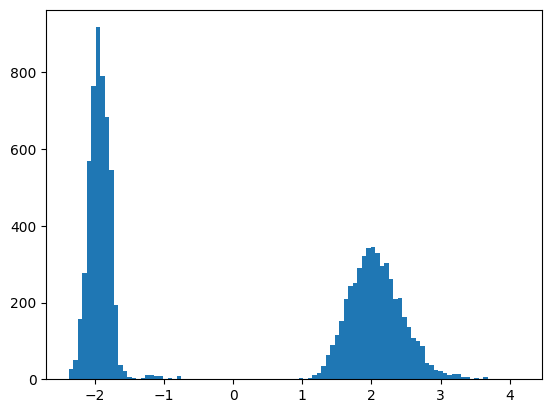

In [ ]:
plt.hist(par0_gamma_gamma[:, 0], bins=100)
plt.show()

In [ ]:
gamma1 = scipy.stats.gamma.rvs(alpha1, theta1, size = 10000)
lognormal1 = scipy.stats.lognorm.rvs(mu1, sigma1, size = 10000)

In [ ]:
m1_gamma_gamma = MBT(n_boosts = 250, learning_rate = 0.1, loss_type = "gamma", refit = False, min_leaf = 2000, lambda_weights=0.1).fit(x, gamma1, do_plot = False)
m1_lognormal_lognormal = MBT(n_boosts = 250, learning_rate = 0.1, loss_type = "lognormal", refit = False, min_leaf = 2000, lambda_weights=0.1).fit(x, lognormal1, do_plot = False)
m1_gamma_lognormal = MBT(n_boosts = 250, learning_rate = 0.1, loss_type = "lognormal", refit = False, min_leaf = 2000, lambda_weights=0.1).fit(x, gamma1, do_plot = False)
m1_lognormal_gamma = MBT(n_boosts = 250, learning_rate = 0.1, loss_type = "gamma", refit = False, min_leaf = 2000, lambda_weights=0.1).fit(x, lognormal1, do_plot = False)

In [ ]:
gamma2 = scipy.stats.gamma.rvs(alpha2, theta2, size = 10000)
lognormal2 = scipy.stats.lognorm.rvs(mu2, sigma2, size = 10000)

In [ ]:
m2_gamma_gamma = MBT(n_boosts = 250, learning_rate = 0.1, loss_type = "gamma", refit = False, min_leaf = 2000, lambda_weights=0.1).fit(x, gamma2, do_plot = False)
m2_lognormal_lognormal = MBT(n_boosts = 250, learning_rate = 0.1, loss_type = "lognormal", refit = False, min_leaf = 2000, lambda_weights=0.1).fit(x, lognormal2, do_plot = False)
m2_gamma_lognormal = MBT(n_boosts = 250, learning_rate = 0.1, loss_type = "lognormal", refit = False, min_leaf = 2000, lambda_weights=0.1).fit(x, gamma2, do_plot = False)
m2_lognormal_gamma = MBT(n_boosts = 250, learning_rate = 0.1, loss_type = "gamma", refit = False, min_leaf = 2000, lambda_weights=0.1).fit(x, lognormal2, do_plot = False)